在 `MR_996_rpts.xyz` 中存放着 42 个反应的反应物、生成物、过渡态 XYZ 三维结构；在 `MR_996_soap.xyz` 中存放着这 42 个反应的其他构型，我们期望通过 DScribe 的描述符，将这些反应中不同的反应区分开来，同时希望观察到每个反应的其他构型分布在反应物、生成物、过渡态的周围。

### 导入所需的第三方库

In [7]:
# 导入所需库：ASE 负责读取结构，DScribe 的 CoulombMatrix 生成描述符，sklearn 做 t-SNE
from ase.io import read
from dscribe.descriptors import CoulombMatrix
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

定义一个函数，用于计算每个分子的 Coulomb 矩阵

In [ ]:
# 用 DScribe 的 CoulombMatrix（库仑矩阵）把不同原子数的分子统一编码为定长向量
def calculate_coulomb_matrices(molecules, max_n_atoms, n_jobs):
    '''
    Calculate Coulomb matrices for a list of molecules.
    Args:
        molecules: List of molecules.
        max_n_atoms: Maximum number of atoms in a molecule.
        n_jobs: Number of jobs to run in parallel.
    Returns:
        Coulomb matrices for the molecules.
    '''
    cm = CoulombMatrix(n_atoms_max=max_n_atoms)
    return cm.create(molecules, n_jobs=n_jobs)

读取并计算两个 XYZ 数据中的库伦矩阵

In [3]:
# 依次读取两个 xyz 数据集，计算其中每个结构的库仑矩阵并按文件名存入字典
n_jobs = 2
xyz_ls = ['MR_996_rpts.xyz', 'MR_996_soap.xyz']
cm_dir = {}

for xyz in xyz_ls:
    print(f"Begin to read {xyz}")
    molecules = read(xyz, index=':')
    print(f"Finished reading {xyz}")

    # 获取原子数的最大值
    max_n_atoms = max(len(mol) for mol in molecules)
    print(f"Maximum number of atoms in a molecule: {max_n_atoms}")

    # 计算库伦矩阵
    print("Begin to calculate Coulomb matrices")
    coulomb_matrices = calculate_coulomb_matrices(molecules, max_n_atoms, n_jobs)
    cm_dir[xyz] = coulomb_matrices
    print("Finished calculating Coulomb matrices")

Begin to read MR_996_rpts.xyz
Finished reading MR_996_rpts.xyz
Maximum number of atoms in a molecule: 28
Begin to calculate Coulomb matrices
Finished calculating Coulomb matrices
Begin to read MR_996_soap.xyz
Finished reading MR_996_soap.xyz
Maximum number of atoms in a molecule: 28
Begin to calculate Coulomb matrices
Finished calculating Coulomb matrices


定义 t-SNE 函数

In [13]:
# t-SNE 降维封装：把展平的库仑矩阵投影到二维，便于观察结构聚类情况
def do_tSNE(tSNE_params, flattened_matrices):
    print('Begin to do t-SNE')
    tsne = TSNE(**tSNE_params)
    reduced_data = tsne.fit_transform(flattened_matrices)
    print('Finish doing t-SNE')
    return reduced_data

In [18]:
# 将所有数据合并
data_list = [cm_dir['MR_996_rpts.xyz'], cm_dir['MR_996_soap.xyz']]
flattened_matrices = np.concatenate(data_list, axis=0)

# 创建标签
labels = np.concatenate(
    [np.full(len(data), i + 1) for i, data in enumerate(data_list)],
    axis=0
)

print('Finish concatenating data')

# 进行 t-SNE 降维
tSNE_params = {'n_components': 2, 'perplexity': 100}
tSNE_result = do_tSNE(tSNE_params, flattened_matrices)

Finish concatenating data
Begin to do t-SNE
Finish doing t-SNE


定义函数绘制 t-SNE 降维聚类图像

In [23]:
# 绘制降维散点图：不同标签（rpts / soap）用不同颜色区分
def draw_clustering_results(reduced_data, labels, legends, name):
    print('Begin to draw clustering results')
    plt.figure(figsize=(8, 8))

    # 设置颜色列表
    colors = [
    '#440154',  # 黄色
    '#FDE724',  # 紫色
]

    # 从最后一个标签开始绘制
    for i in range(len(legends) - 1, -1, -1):
        mask = labels == (i + 1)  # 标签从 1 开始
        plt.scatter(reduced_data[mask, 0], reduced_data[mask, 1], 
                    color=colors[i % len(colors)], alpha=0.7, s=1, label=legends[i])

    # 添加图例
    plt.legend()
    plt.title(f'{name} Visualization of Molecular Structures with Coulomb Matrices')
    plt.xlabel(f'{name} Component 1')
    plt.ylabel(f'{name} Component 2')
    plt.show()
    print(f'Finish drawing clustering results {name}.png')

Begin to draw clustering results


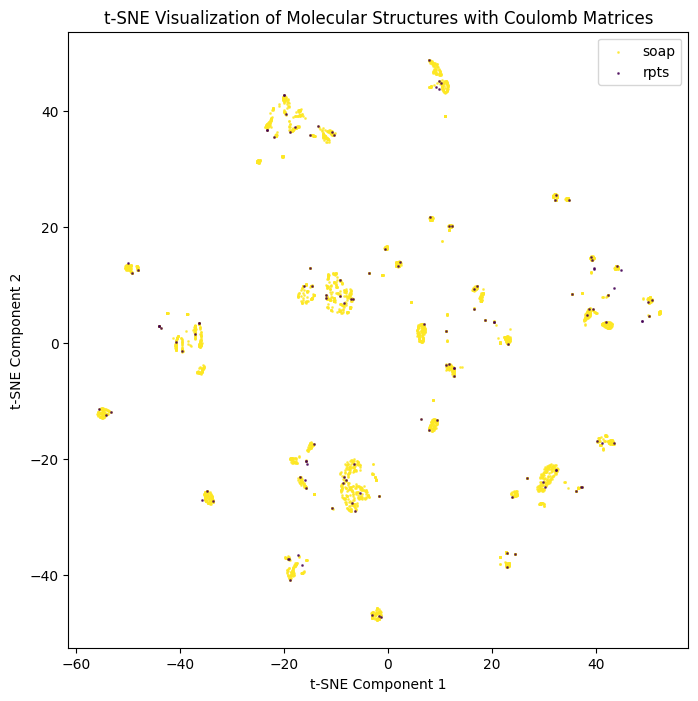

Finish drawing clustering results t-SNE.png
Finish drawing t-SNE clustering results


In [24]:
# 传入 t-SNE 结果、标签与图例名，绘制最终的聚类散点图
legends = ['rpts', 'soap']
draw_clustering_results(tSNE_result, labels, legends, 't-SNE')
print('Finish drawing t-SNE clustering results')

可以看到，t-SNE 降维后，分子结构在二维空间中得到了较好的聚类效果，不同类别的分子结构被比较清晰地分离开来。并且黄色的点（该反应的其他结构）都在紫色的点（反应物、过渡态、生成物）附近。我们还可以尝试更换描述符，在同样的数据集上可以取得下面的结果：

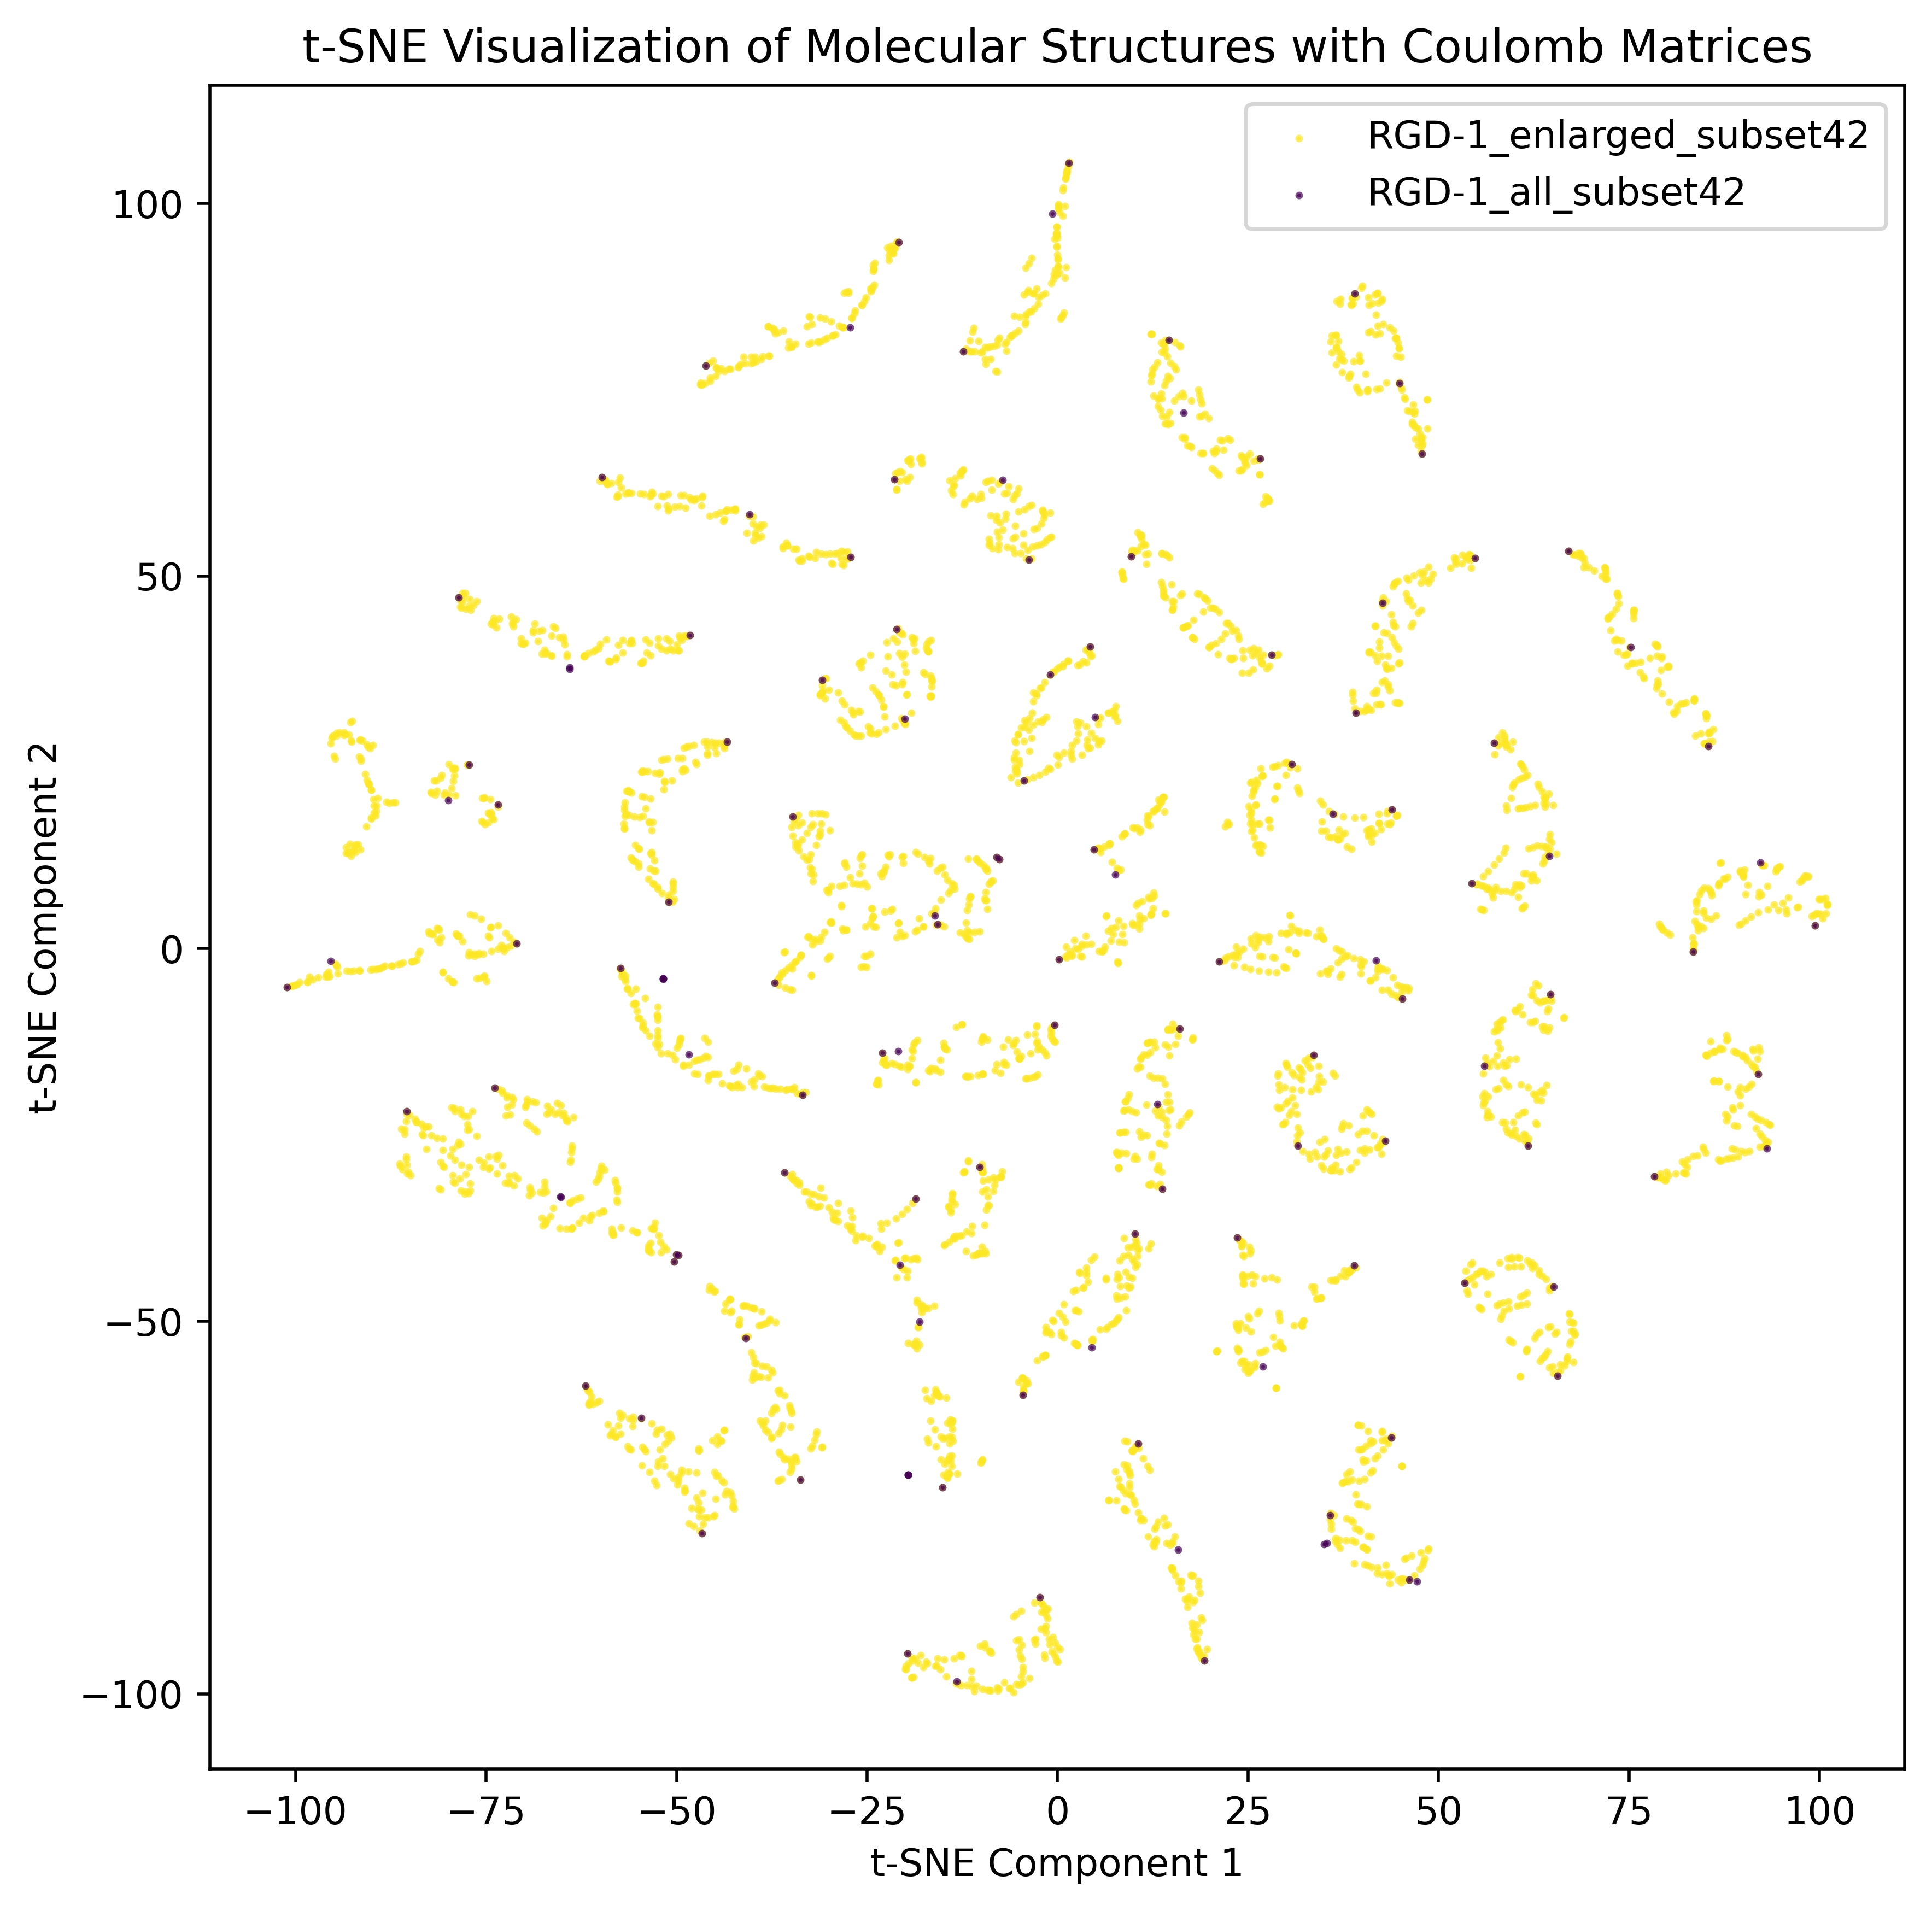